All image number: 940
Class Number: 89


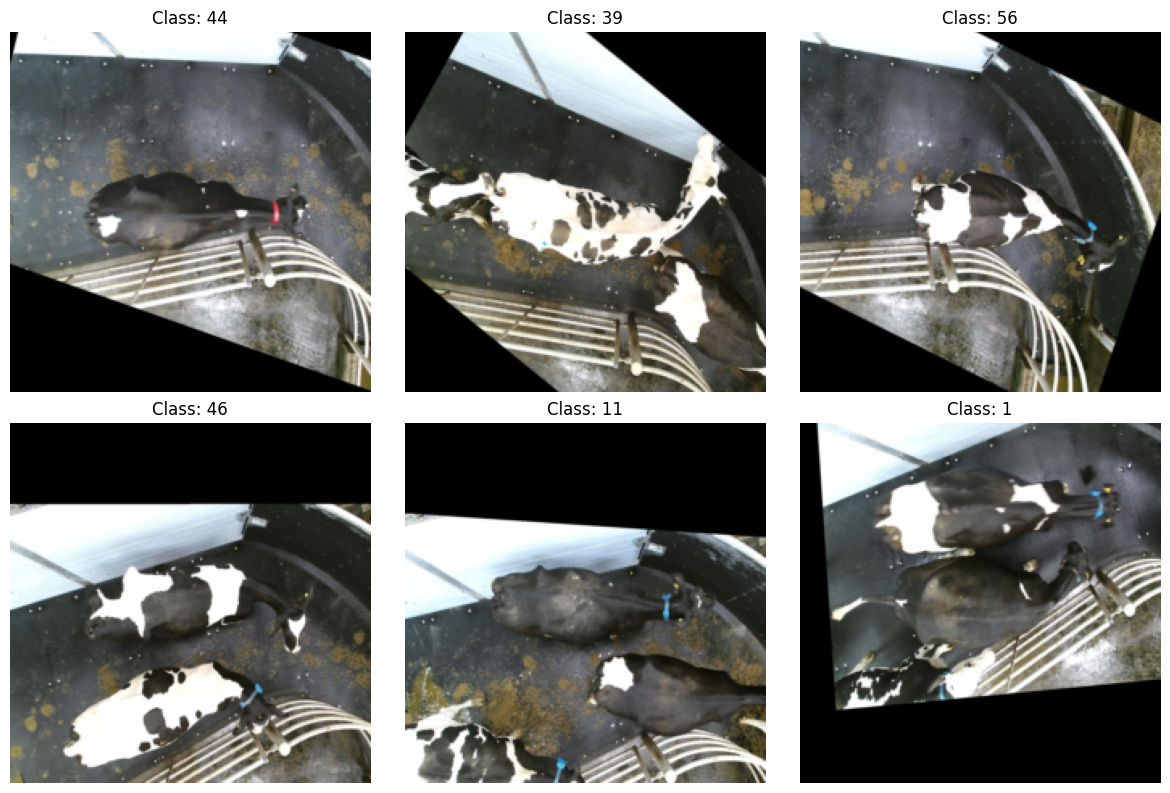

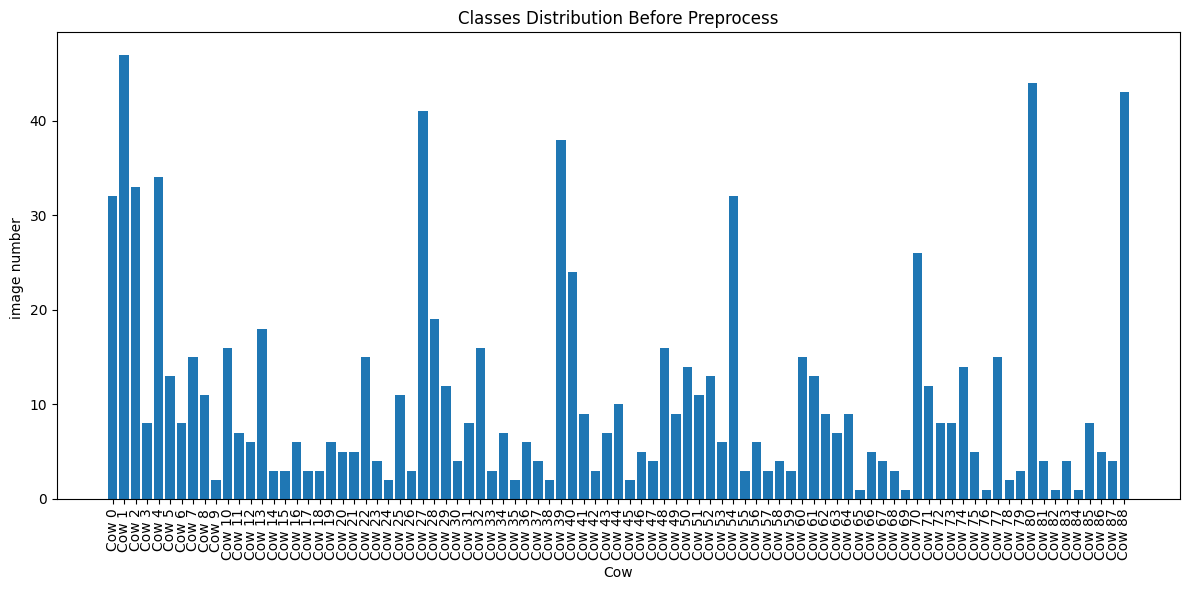

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from PIL import Image
import os
import random
from collections import defaultdict, Counter
import numpy as np

# ================================================
# بخش ۱-۱: آماده‌سازی داده‌ها (Data Preparation)
# ================================================

dataset_path = '/kaggle/input/datasets/aliaqa12m/cow-dataset/2yizcfbkuv4352pzc32n54371r'

def show_samples(dataset, num_samples=6):
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    axes = axes.ravel()
    indices = random.sample(range(len(dataset)), num_samples)
    for i, idx in enumerate(indices):
        img, label = dataset[idx]
        axes[i].imshow(img.permute(1, 2, 0).numpy())
        axes[i].set_title(f'Class: {dataset.classes[label]}')
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

def plot_class_distribution(class_counts, title="Number Of Images per Class"):
    classes = list(class_counts.keys())
    counts = list(class_counts.values())
    plt.figure(figsize=(12, 6))
    plt.bar(range(len(classes)), counts)
    plt.xticks(range(len(classes)), [f'Cow {c}' for c in classes], rotation=90)
    plt.xlabel('Cow')
    plt.ylabel('image number ')
    plt.title(title)
    plt.tight_layout()
    plt.show()


# ترنسفورم اولیه برای بررسی (بدون نرمال‌سازی)
initial_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# استفاده از ImageFolder برای بارگذاری اولیه
full_dataset = datasets.ImageFolder(dataset_path, transform=initial_transform)

print(f"All image number: {len(full_dataset)}")
print(f"Class Number: {len(full_dataset.classes)}")

# نمایش چند نمونه
show_samples(full_dataset)

# شمارش تعداد تصاویر در هر کلاس
class_counts = Counter([label for _, label in full_dataset.samples])
plot_class_distribution(class_counts, "Classes Distribution Before Preprocess")


In [2]:
# جمع‌آوری تصاویر هر کلاس
class_images = defaultdict(list)
for path, cls_idx in full_dataset.samples:
    class_images[cls_idx].append(path)

# کلاس‌هایی که حداقل ۵ تصویر دارند
valid_classes = [cls for cls, imgs in class_images.items() if len(imgs) >= 5]
print(f"class after remove small class: {len(valid_classes)}")

# نقشه‌برداری کلاس‌های قدیمی به جدید (برای consecutive labels)
class_map = {old_cls: new_idx for new_idx, old_cls in enumerate(valid_classes)}

# ترنسفورم‌های آموزش و تست
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# کلاس دیتاست سفارشی برای نمونه‌های فیلترشده
class FilteredCowDataset(Dataset):
    def __init__(self, samples, transform=None, inc = 1):
        self.samples = samples  # لیست از (path, label)
        self.transform = transform
        self.inc = inc
    def __len__(self):
        return len(self.samples) * self.inc
    
    def __getitem__(self, idx):
        idx = idx // self.inc
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label


class after remove small class: 57


In [3]:

import torchvision.transforms as transforms

train_transform = transforms.Compose([
    # ── PIL Image operations ───────────────────────────────
    transforms.Resize(256),                     # safe starting size
    
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.75, 1.0),                      # don't crop away too much identity
        ratio=(0.9, 1.1)
    ),
    
    transforms.RandomHorizontalFlip(p=0.5),
    
    transforms.RandomRotation(degrees=18),
    
    transforms.RandomAffine(
        degrees=0,
        translate=(0.10, 0.10),
        scale=(0.92, 1.08),
        shear=8
    ),
    
    transforms.ColorJitter(
        brightness=0.18,
        contrast=0.18,
        saturation=0.12,
        hue=0.06
    ),
    
    transforms.RandomPerspective(
        distortion_scale=0.14,
        p=0.35
    ),
    
    transforms.GaussianBlur(
        kernel_size=(5, 9),
        sigma=(0.1, 1.2)
    ),
    
    # ── Convert to tensor ─────────────────────────────────
    transforms.ToTensor(),
    
    # ── Tensor operations ─────────────────────────────────
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    
    transforms.RandomErasing(                   # good for re-identification
        p=0.30,
        scale=(0.02, 0.18),
        ratio=(0.3, 3.3)
    ),
])

test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 1-2

Number of training samples: 2628
Number of test samples:     194
Number of classes:           57


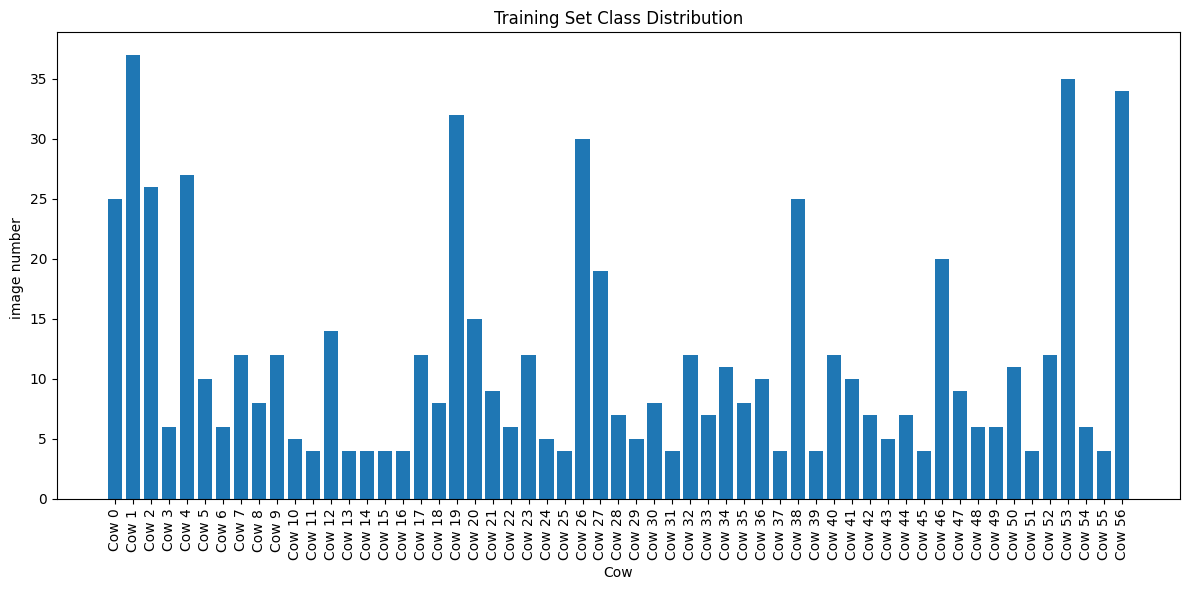

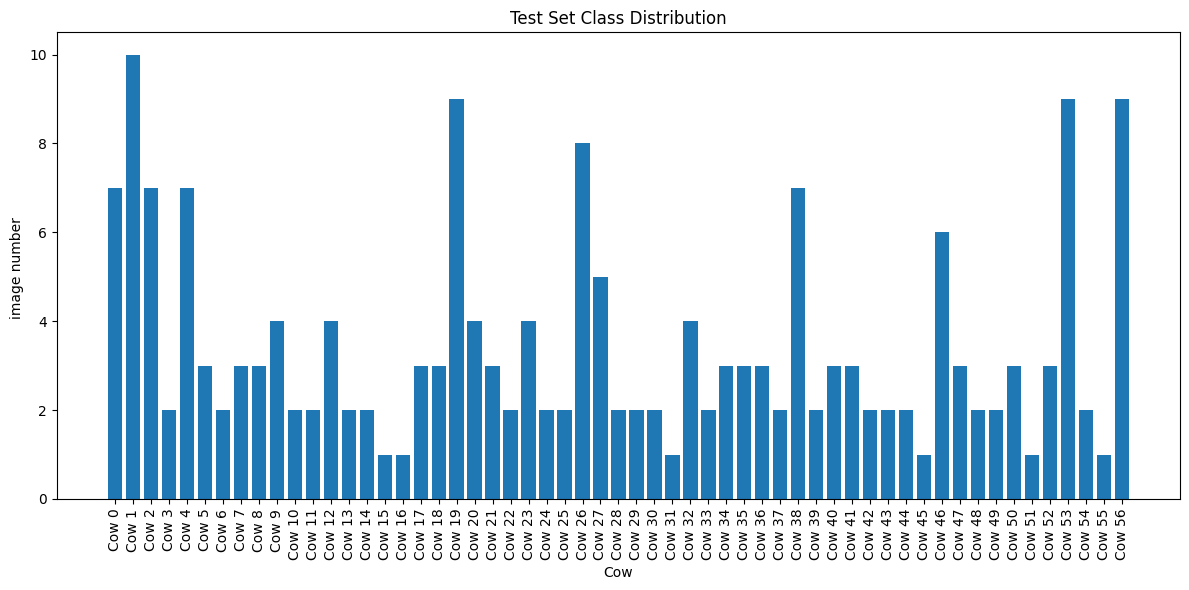

In [4]:
# ================================================
# Part 1-2: Dataset Splitting (80/20 random split – no Graph Sampling)
# ================================================

# About Graph Sampling (from the paper):
# Graph Sampling models images as nodes in a graph (edges = feature similarity).
# It performs sampling from this graph to create balanced train/test splits.
# This is especially useful in re-identification tasks with imbalanced and
# identity-specific data (like cow coat patterns), reducing bias and improving
# generalization. In this exercise we use a standard random 80/20 split instead.

train_samples = []
test_samples = []

for old_cls, paths in class_images.items():
    if old_cls not in class_map:
        continue
    new_label = class_map[old_cls]
    random.shuffle(paths)
    num_train = int(0.8 * len(paths))
    for p in paths[:num_train]:
        train_samples.append((p, new_label))
    for p in paths[num_train:]:
        test_samples.append((p, new_label))

train_dataset = FilteredCowDataset(train_samples, transform=train_transform, inc=4)
test_dataset = FilteredCowDataset(test_samples, transform=test_transform)

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of test samples:     {len(test_dataset)}")
print(f"Number of classes:           {len(valid_classes)}")

# Show distribution after split
train_class_counts = Counter([label for _, label in train_samples])
test_class_counts  = Counter([label for _, label in test_samples])
plot_class_distribution(train_class_counts,  "Training Set Class Distribution")
plot_class_distribution(test_class_counts,   "Test Set Class Distribution")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epoch 1/20 | Train Loss: 3.3512 | Train Acc: 19.63% | Val Loss:   2.9747   | Val Acc:   31.44%
Epoch 2/20 | Train Loss: 1.8523 | Train Acc: 48.25% | Val Loss:   2.8232   | Val Acc:   36.60%
Epoch 3/20 | Train Loss: 1.3375 | Train Acc: 61.15% | Val Loss:   1.6708   | Val Acc:   48.45%
Epoch 4/20 | Train Loss: 1.0070 | Train Acc: 70.47% | Val Loss:   0.7930   | Val Acc:   72.16%
Epoch 5/20 | Train Loss: 0.7376 | Train Acc: 77.05% | Val Loss:   0.9720   | Val Acc:   65.98%
Epoch 6/20 | Train Loss: 0.6531 | Train Acc: 79.07% | Val Loss:   0.9216   | Val Acc:   69.59%
Epoch 7/20 | Train Loss: 0.5693 | Train Acc: 83.71% | Val Loss:   0.9986   | Val Acc:   73.71%
Epoch 8/20 | Train Loss: 0.5150 | Train Acc: 85.73% | Val Loss:   0.5640   | Val Acc:   78.87%
Epoch 9/20 | Train Loss: 0.4605 | Train Acc: 87.10% | Val Loss:   0.4195   | Val Acc:   87.63%
Epoch 10/20 | Train Loss: 0.2809 | Train Acc: 91.48% | Val Loss:   0.9963   | Val Acc:   72.68%
Epoch 11/20 | Train Loss: 0.3418 | Train Acc: 89.

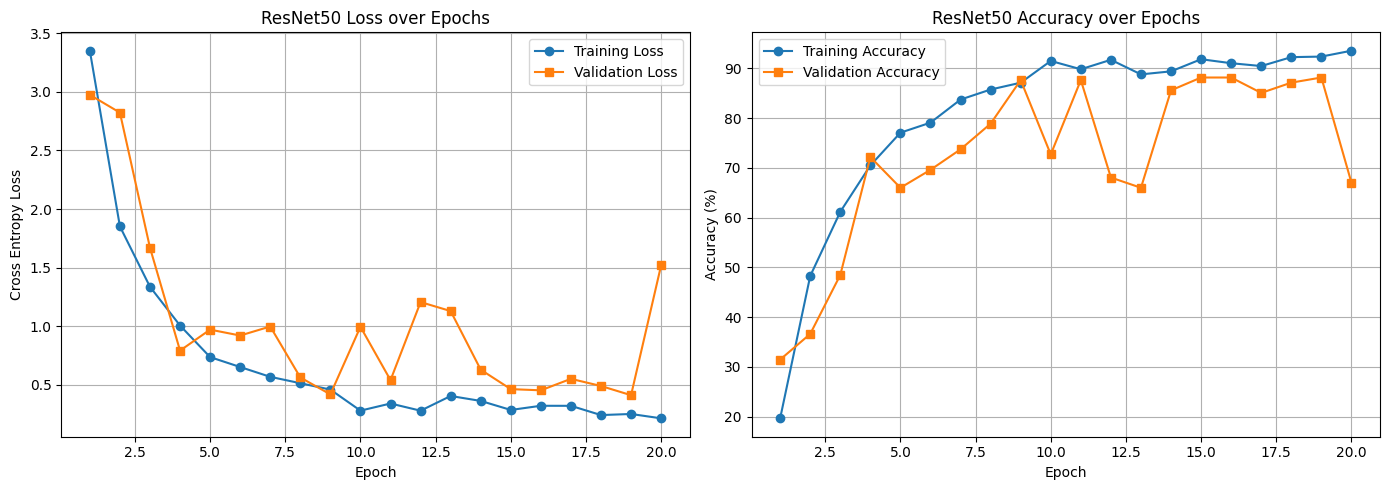

Training completed. Model saved as 'resnet50_cow_reid.pth'


In [5]:

num_classes = len(valid_classes)
model = models.resnet50(pretrained=False)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0005)   # small l4r for fine-tuning

batch_size = 32   # adjust based on your GPU memory
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, num_workers=4)

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=20):
    train_losses = []
    val_losses = []
    
    for epoch in range(num_epochs):
        # Training
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)
        
        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
        val_loss /= len(val_loader)
        val_losses.append(val_loss)
        
        print(f'Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}')
    
    return train_losses, val_losses


def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=20):
    train_losses = []
    val_losses   = []
    train_accs   = []    # ← new
    val_accs     = []    # ← new
    
    for epoch in range(num_epochs):
        # Training
        model.train()
        running_loss = 0.0
        correct      = 0
        total        = 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            
            # Accuracy calculation
            _, predicted = torch.max(outputs.data, 1)
            total   += labels.size(0)
            correct += (predicted == labels).sum().item()
        
        train_loss = running_loss / len(train_loader)
        train_accuracy = 100.0 * correct / total
        
        train_losses.append(train_loss)
        train_accs.append(train_accuracy)     # ← new
        
        # Validation
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val   = 0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                
                # Accuracy
                _, predicted = torch.max(outputs.data, 1)
                total_val   += labels.size(0)
                correct_val += (predicted == labels).sum().item()
        
        val_loss /= len(val_loader)
        val_accuracy = 100.0 * correct_val / total_val
        
        val_losses.append(val_loss)
        val_accs.append(val_accuracy)          # ← new
        
        # Print both loss and accuracy
        print(f'Epoch {epoch+1}/{num_epochs} | '
              f'Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.2f}% | '
              f'Val Loss:   {val_loss:.4f}   | Val Acc:   {val_accuracy:.2f}%')
    
    return train_losses, val_losses, train_accs, val_accs   # ← return 4 lists now


# Train the model (at least 20 epochs)
train_losses, val_losses, train_accs, val_accs = train_model(model, train_loader, test_loader, criterion, optimizer, num_epochs=20)

# Plot Loss and Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Loss curves
ax1.plot(range(1, len(train_losses)+1), train_losses, label='Training Loss', marker='o')
ax1.plot(range(1, len(val_losses)+1),   val_losses,   label='Validation Loss', marker='s')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross Entropy Loss')
ax1.set_title('ResNet50 Loss over Epochs')
ax1.legend()
ax1.grid(True)

# Right: Accuracy curves
ax2.plot(range(1, len(train_accs)+1), train_accs, label='Training Accuracy', marker='o')
ax2.plot(range(1, len(val_accs)+1),   val_accs,   label='Validation Accuracy', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('ResNet50 Accuracy over Epochs')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Optional: save the model
torch.save(model.state_dict(), 'resnet50_cow_reid.pth')
print("Training completed. Model saved as 'resnet50_cow_reid.pth'")

In [6]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=20):
    train_losses = []
    val_losses   = []
    train_accs   = []    # ← new
    val_accs     = []    # ← new
    
    for epoch in range(num_epochs):
        # Training
        model.train()
        running_loss = 0.0
        correct      = 0
        total        = 0
        
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item()
            
            # Accuracy calculation
            _, predicted = torch.max(outputs.data, 1)
            total   += labels.size(0)
            correct += (predicted == labels).sum().item()
        
        train_loss = running_loss / len(train_loader)
        train_accuracy = 100.0 * correct / total
        
        train_losses.append(train_loss)
        train_accs.append(train_accuracy)     # ← new
        
        # Validation
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val   = 0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                
                # Accuracy
                _, predicted = torch.max(outputs.data, 1)
                total_val   += labels.size(0)
                correct_val += (predicted == labels).sum().item()
        
        val_loss /= len(val_loader)
        val_accuracy = 100.0 * correct_val / total_val
        
        val_losses.append(val_loss)
        val_accs.append(val_accuracy)          # ← new
        
        # Print both loss and accuracy
        print(f'Epoch {epoch+1}/{num_epochs} | '
              f'Train Loss: {train_loss:.4f} | Train Acc: {train_accuracy:.2f}% | '
              f'Val Loss:   {val_loss:.4f}   | Val Acc:   {val_accuracy:.2f}%')
    
    return train_losses, val_losses, train_accs, val_accs   # ← return 4 lists now

In [7]:
import torch
import torch.nn as nn
import torchvision.models as models


import weakref

# ==========================================
# Lightweight BoTBlock
# ==========================================
class BoTBlock(nn.Module):
    expansion = 4

    def __init__(self, inplanes, planes, heads=8):
        super().__init__()
        attention_dim = planes * self.expansion  # 1024 or 2048 depending on stage

        self.conv1 = nn.Conv2d(inplanes, attention_dim, kernel_size=1, bias=False)
        self.bn1   = nn.BatchNorm2d(attention_dim)
        self.relu  = nn.ReLU(inplace=True)

        self.mhsa = nn.MultiheadAttention(
            embed_dim=attention_dim,
            num_heads=heads,
            batch_first=True
        )

        # self.conv2 = nn.Conv2d(attention_dim, attention_dim, kernel_size=1, bias=False)
        self.bn2   = nn.BatchNorm2d(attention_dim)

        self.conv3 = nn.Conv2d(attention_dim, planes * self.expansion, kernel_size=1, bias=False)
        self.bn3 = nn.BatchNorm2d(planes * self.expansion)

        self.downsample = None
        if inplanes != attention_dim:
            self.downsample = nn.Sequential(
                nn.Conv2d(inplanes, attention_dim, kernel_size=1, bias=False),
                nn.BatchNorm2d(attention_dim)
            )

    def forward(self, x):
        identity = x
    
        out = self.relu(self.bn1(self.conv1(x)))
    
        B, C, H, W = out.shape
        out_flat = out.flatten(2).transpose(1, 2)
    
        attn_out, attn_weights = self.mhsa(out_flat, out_flat, out_flat)
    
        out = attn_out.transpose(1, 2).view(B, C, H, W)
        out = self.relu(self.bn2(out))
    
        out = self.bn3(self.conv3(out))
    
        if self.downsample is not None:
            identity = self.downsample(x)
    
        out += identity
        out = self.relu(out)
    
        if hasattr(self, "model_ref") and self.model_ref is not None:
            model = self.model_ref()
            if model is not None and model.extract_attention:
                model.attention_maps.append(attn_weights.detach().cpu())
    
        return out



class BoTNet50(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        # Load pretrained ResNet50
        backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        self.backbone = backbone
        # Keep early layers
        self.conv1   = backbone.conv1
        self.bn1     = backbone.bn1
        self.relu    = backbone.relu
        self.maxpool = backbone.maxpool

        self.layer1  = backbone.layer1
        self.layer2  = backbone.layer2

        # Replace layer3 and layer4 with BoTBlocks
        self.layer3 = nn.Sequential(
            BoTBlock(512, 256),
            BoTBlock(1024, 256),
            BoTBlock(1024, 256)
        )

        self.layer4 = nn.Sequential(
            BoTBlock(1024, 512),
            BoTBlock(2048, 512)
        )
        self.extract_attention = False
        self.attention_maps = []

        for layer in [self.layer3, self.layer4]:
            for block in layer:
                block.model_ref = weakref.ref(self)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x


import sys
sys.setrecursionlimit(3000)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ============================================================
# Instantiate model
# ============================================================
num_classes = len(valid_classes)# from your previous code
print(num_classes)
model_botnet = BoTNet50(num_classes=num_classes).to(device)
print(device)
print(model_botnet)                       # Full architecture is printed/saved in code
# torchsummary.summary(model_botnet, (3, 224, 224))   # optional

57
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


cuda
BoTNet50(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
   

In [8]:
for param in model_botnet.backbone.parameters():
    param.requires_grad = False

# ============================================================
# Training (same as ResNet50 part)
# ============================================================
criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model_botnet.parameters(), lr=0.0003)   # slightly lower lr recommended
optimizer = optim.SGD(model_botnet.parameters(), lr=0.001, momentum=0.9, weight_decay=1e-4)



batch_size = 16      # BoTNet is heavier → reduce from 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)

# Training loop (same as before)
train_losses, val_losses, train_accs, val_accs = train_model(
    model_botnet, train_loader, test_loader, criterion, optimizer, num_epochs=20
)
# train_losses, val_losses = train_model(model_botnet, train_loader, test_loader, criterion, optimizer, num_epochs=20)

# Save model
torch.save(model_botnet.state_dict(), 'botnet50_cow_reid.pth')


Epoch 1/20 | Train Loss: 3.3321 | Train Acc: 20.81% | Val Loss:   2.3324   | Val Acc:   38.14%
Epoch 2/20 | Train Loss: 1.9667 | Train Acc: 44.86% | Val Loss:   1.9003   | Val Acc:   46.39%
Epoch 3/20 | Train Loss: 1.3363 | Train Acc: 60.39% | Val Loss:   1.3012   | Val Acc:   59.28%
Epoch 4/20 | Train Loss: 0.9913 | Train Acc: 68.80% | Val Loss:   1.4782   | Val Acc:   56.19%
Epoch 5/20 | Train Loss: 0.7397 | Train Acc: 77.40% | Val Loss:   0.7170   | Val Acc:   81.96%
Epoch 6/20 | Train Loss: 0.5846 | Train Acc: 81.66% | Val Loss:   0.4676   | Val Acc:   85.57%
Epoch 7/20 | Train Loss: 0.4994 | Train Acc: 83.98% | Val Loss:   0.6202   | Val Acc:   80.93%
Epoch 8/20 | Train Loss: 0.3848 | Train Acc: 87.71% | Val Loss:   0.4867   | Val Acc:   86.60%
Epoch 9/20 | Train Loss: 0.3369 | Train Acc: 88.96% | Val Loss:   0.4147   | Val Acc:   89.69%
Epoch 10/20 | Train Loss: 0.2819 | Train Acc: 90.91% | Val Loss:   0.4669   | Val Acc:   87.63%
Epoch 11/20 | Train Loss: 0.1963 | Train Acc: 93.

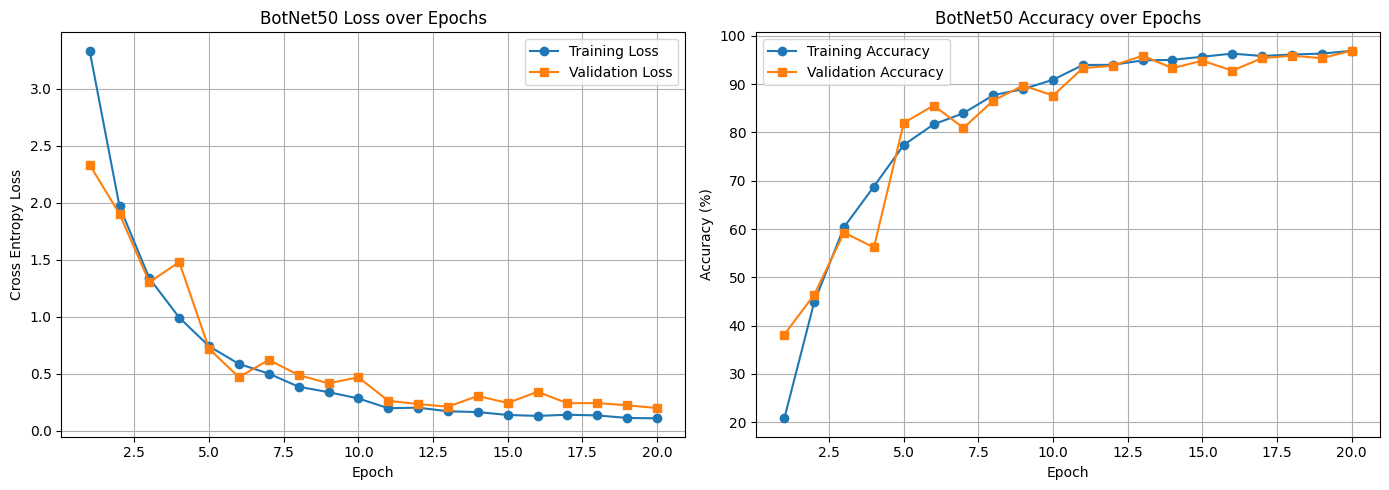

In [9]:
# Plot Loss and Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Loss curves
ax1.plot(range(1, len(train_losses)+1), train_losses, label='Training Loss', marker='o')
ax1.plot(range(1, len(val_losses)+1),   val_losses,   label='Validation Loss', marker='s')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross Entropy Loss')
ax1.set_title('BotNet50 Loss over Epochs')
ax1.legend()
ax1.grid(True)

# Right: Accuracy curves
ax2.plot(range(1, len(train_accs)+1), train_accs, label='Training Accuracy', marker='o')
ax2.plot(range(1, len(val_accs)+1),   val_accs,   label='Validation Accuracy', marker='s')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('BotNet50 Accuracy over Epochs')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

/tmp/ipykernel_23/305923584.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('jet')


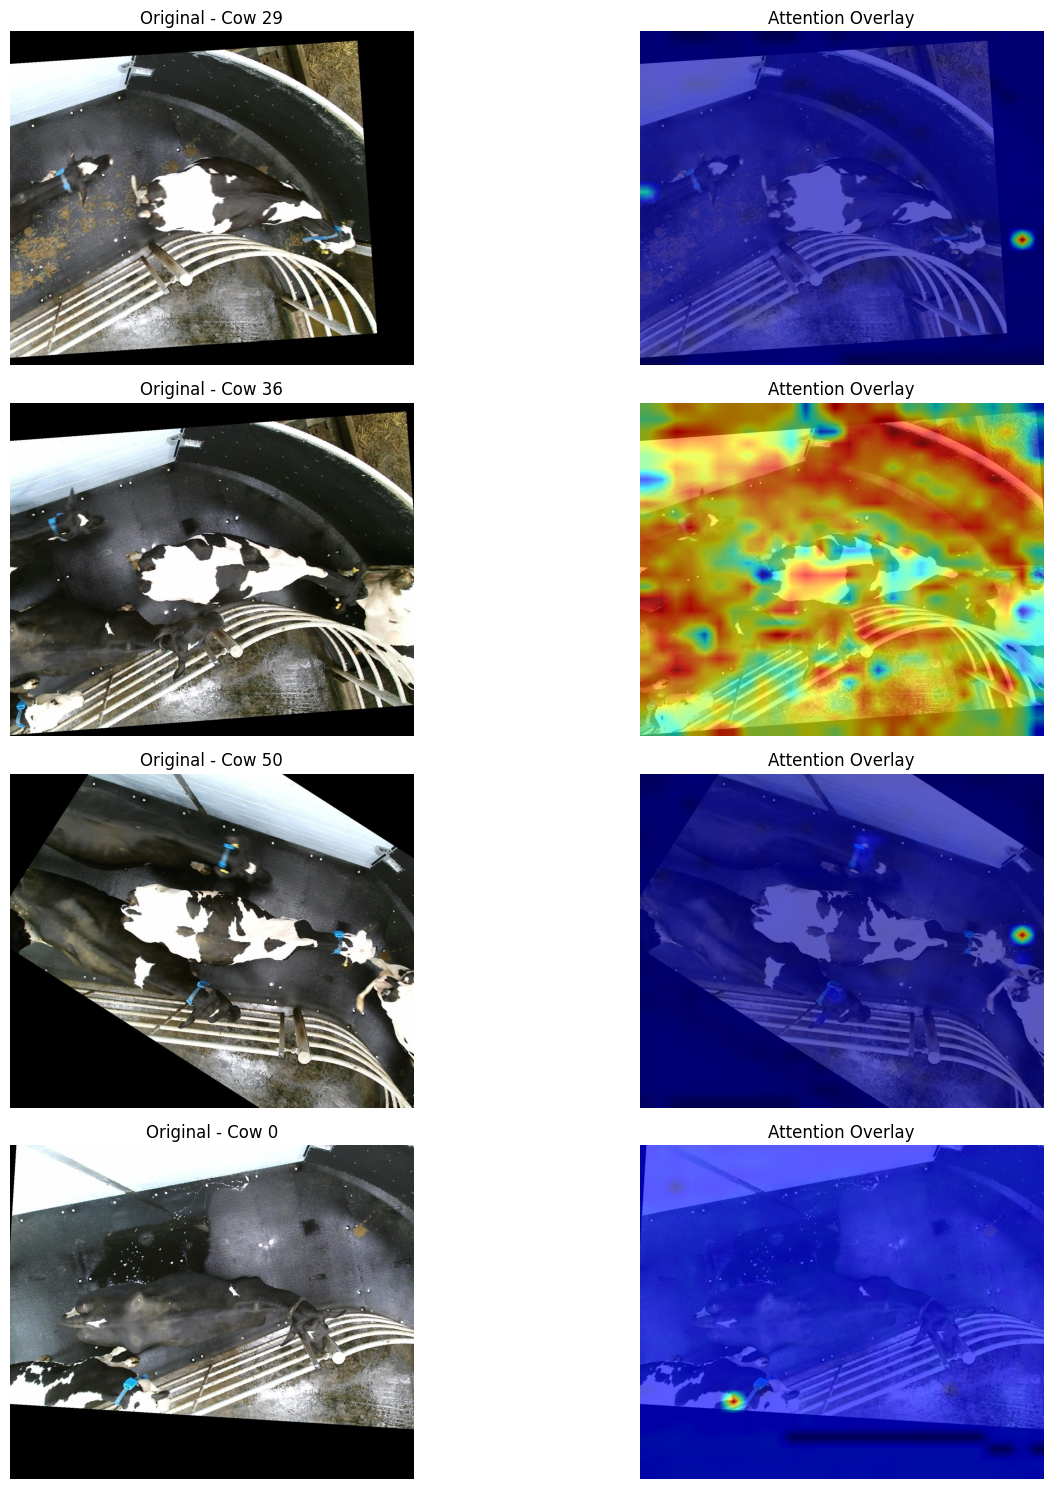

In [10]:
import cv2
from PIL import Image
import matplotlib.cm as cm



# ============================================================
# Part 1-5: Attention Heatmaps (exactly as required)
# ============================================================
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(tensor.device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(tensor.device)
    return tensor * std + mean


def generate_heatmap_overlay(model, image_tensor, original_pil, attn_idx=2):
    model.extract_attention = True
    model.attention_maps = []

    with torch.no_grad():
        _ = model(image_tensor.unsqueeze(0).to(device))

    if not model.attention_maps:
        print("No attention maps collected")
        return None, None

    attn = model.attention_maps[attn_idx][0]           # (N, N)
    N = attn.shape[0]
    spatial_dim = int(np.sqrt(N))

    if spatial_dim * spatial_dim != N:
        print(f"Attention size {N} is not square → cannot reshape")
        return None, None

    # Collapse attention matrix to spatial map
    attn_spatial = attn.mean(dim=0)                    # (N,)
    attn_spatial = (attn_spatial - attn_spatial.min()) / \
                   (attn_spatial.max() - attn_spatial.min() + 1e-8)

    attn_map = attn_spatial.view(spatial_dim, spatial_dim)  # (14,14) or (7,7) etc.

    # ────────────────────────────────────────────────
    # Get original image as numpy array (H_orig, W_orig, 3)
    # ────────────────────────────────────────────────
    img_orig = np.array(original_pil) / 255.0          # [0,1] range
    h_orig, w_orig = img_orig.shape[:2]

    # Upsample attention to **original** image size
    attn_up = nn.functional.interpolate(
        attn_map.unsqueeze(0).unsqueeze(0).float(),    # (1,1,h,w)
        size=(h_orig, w_orig),
        mode='bilinear',
        align_corners=False
    ).squeeze().cpu().numpy()                          # (h_orig, w_orig)

    # Create colored heatmap
    cmap = cm.get_cmap('jet')
    heatmap = cmap(attn_up)[:, :, :3]                  # (h_orig, w_orig, 3)

    # Blend: weighted sum
    alpha = 0.65
    overlay = heatmap * alpha + img_orig * (1 - alpha)

    # Return overlay and original (both in [0,1])
    return overlay, img_orig

# Visualization for several samples (run on test set)
model_botnet.eval()
fig, axes = plt.subplots(4, 2, figsize=(15, 15))
axes = axes.ravel()

samples_to_show = 4
indices = np.random.choice(len(test_dataset), samples_to_show, replace=False)

for i, idx in enumerate(indices):
    img_tensor, label = test_dataset[idx]
    orig_pil = Image.open(test_dataset.samples[idx][0]).convert('RGB')

    overlay, orig = generate_heatmap_overlay(model_botnet, img_tensor, orig_pil, attn_idx=2)

    axes[2*i].imshow(orig)
    axes[2*i].set_title(f"Original - Cow {label}")
    axes[2*i].axis('off')

    axes[2*i+1].imshow(overlay)
    axes[2*i+1].set_title("Attention Overlay")
    axes[2*i+1].axis('off')

plt.tight_layout()
plt.show()

# After running, visually inspect and answer:
# → Does the model focus on coat patterns or background?
# → Find and save one example where attention is clearly on irrelevant background (fence, ground, other cow, tag, etc.)